# BB84 QKD under Noise and Eavesdropping (Qiskit)
**IEG 313 - Team Bell State Bandits**

All logic lives in `bb84_qkd.py` (fully commented, one block per protocol step). This notebook just runs it and shows the outputs.

In [ ]:
# Run once if something is missing, then restart the kernel
# !pip install -r requirements.txt

## 1. Import

In [1]:
%matplotlib inline
from bb84_qkd import *
set_seed(42)   # remove for different random bits each run

## 2. One qubit's circuit
Bob's example: Alice sends bit 1 in the **X** basis, Bob measures in **Z**, channel is noisy (`id` gate).

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


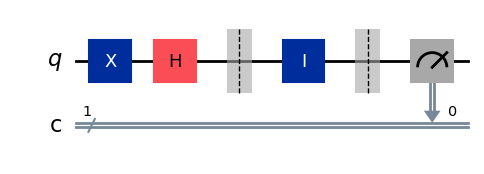

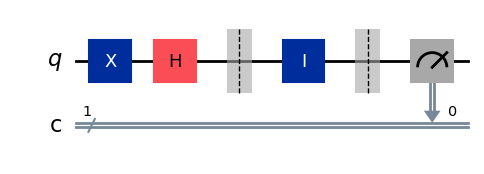

In [2]:
build_circuit(bit=1, prep_basis=1, meas_basis=0, noisy=True).draw('mpl')

## 3. Demo without Eve (5% noise)
Expect: low QBER, key **ACCEPTED**.

In [3]:
run_bb84(noise=0.05, eve=False, verbose=True);

Settings              : noise=5.0%, Eve=OFF
Qubits sent           : 10000
Sifted bits           : 4984
Sample revealed       : 1246
Estimated QBER        : 4.65%
Approx. 95% QBER CI   : [3.62%, 5.97%]
Simulator-only QBER   : 4.90%
Remaining candidate bits: 3738
Accepted key length   : 3738
Decision              : ACCEPT
Note: accepted length is a teaching metric, not a secure final key.


## 4. Demo with Eve (5% noise)
Expect: QBER about 25% or more, key **REJECTED**.

In [4]:
run_bb84(noise=0.05, eve=True, verbose=True);

Settings              : noise=5.0%, Eve=ON
Qubits sent           : 10000
Sifted bits           : 4981
Sample revealed       : 1245
Estimated QBER        : 30.92%
Approx. 95% QBER CI   : [28.42%, 33.55%]
Simulator-only QBER   : 30.54%
Remaining candidate bits: 3736
Accepted key length   : 0
Decision              : REJECT
Note: accepted length is a teaching metric, not a secure final key.


## 5. Full experiment: noise 0-20%, with and without Eve

In [5]:
summary = noise_experiment(trials=5)
summary.round(3)

Completed: Eve=OFF, noise=0%
Completed: Eve=OFF, noise=2%
Completed: Eve=OFF, noise=4%
Completed: Eve=OFF, noise=6%
Completed: Eve=OFF, noise=8%
Completed: Eve=OFF, noise=10%
Completed: Eve=OFF, noise=12%
Completed: Eve=OFF, noise=14%
Completed: Eve=OFF, noise=16%
Completed: Eve=OFF, noise=18%
Completed: Eve=OFF, noise=20%
Completed: Eve=ON, noise=0%
Completed: Eve=ON, noise=2%
Completed: Eve=ON, noise=4%
Completed: Eve=ON, noise=6%
Completed: Eve=ON, noise=8%
Completed: Eve=ON, noise=10%
Completed: Eve=ON, noise=12%
Completed: Eve=ON, noise=14%
Completed: Eve=ON, noise=16%
Completed: Eve=ON, noise=18%
Completed: Eve=ON, noise=20%


,eve,noise,estimated_qber,estimated_qber_std,simulator_true_qber,simulator_true_qber_std,mean_sifted_bits,mean_sample_size,mean_key_agreement,mean_candidate_key_len,mean_accepted_key_len,acceptance_rate,eve_label
0,False,0.00,0.000,0.000,0.000,0.000,4990.4,1247.2,1.000,3743.2,3743.2,1.0,No Eve
1,False,0.02,0.023,0.005,0.021,0.003,4962.2,1240.2,0.980,3722.0,3722.0,1.0,No Eve
2,False,0.04,0.039,0.004,0.038,0.002,4978.8,1244.4,0.962,3734.4,3734.4,1.0,No Eve
3,False,0.06,0.060,0.004,0.062,0.004,4979.8,1244.6,0.938,3735.2,3735.2,1.0,No Eve
4,False,0.08,0.085,0.005,0.081,0.003,4967.0,1241.2,0.921,3725.8,3725.8,1.0,No Eve
5,False,0.10,0.101,0.005,0.102,0.002,5024.0,1255.6,0.898,3768.4,3768.4,1.0,No Eve
6,False,0.12,0.124,0.008,0.118,0.005,4998.4,1249.2,0.883,3749.2,0.0,0.0,No Eve
7,False,0.14,0.143,0.015,0.140,0.006,4963.0,1240.4,0.861,3722.6,0.0,0.0,No Eve
8,False,0.16,0.163,0.011,0.158,0.004,4995.8,1248.4,0.843,3747.4,0.0,0.0,No Eve
9,False,0.18,0.180,0.010,0.184,0.004,5007.0,1251.4,0.815,3755.6,0.0,0.0,No Eve


## 6. Graphs

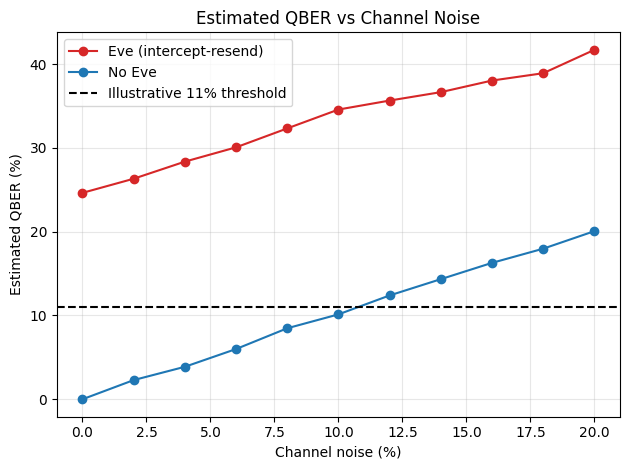

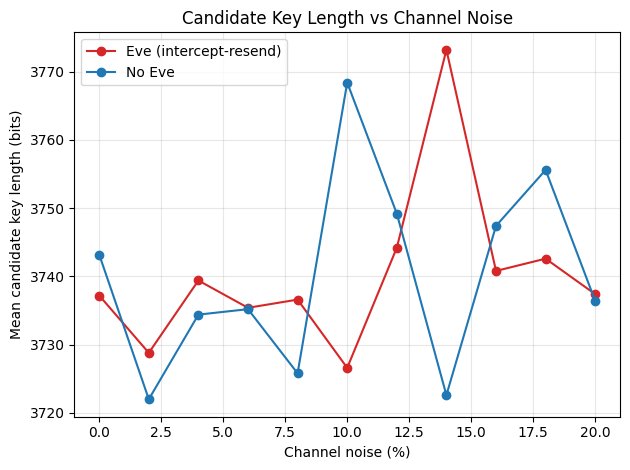

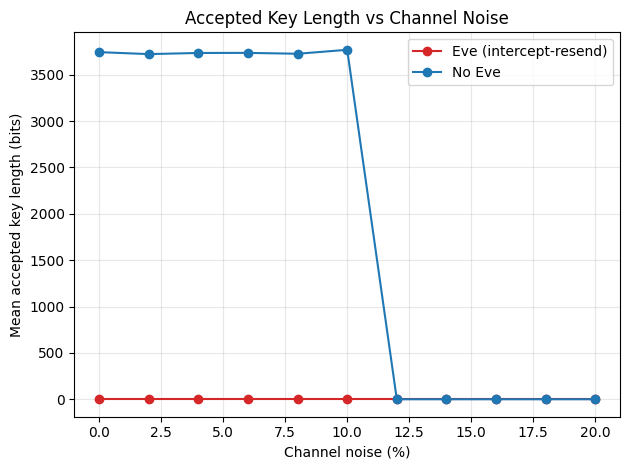

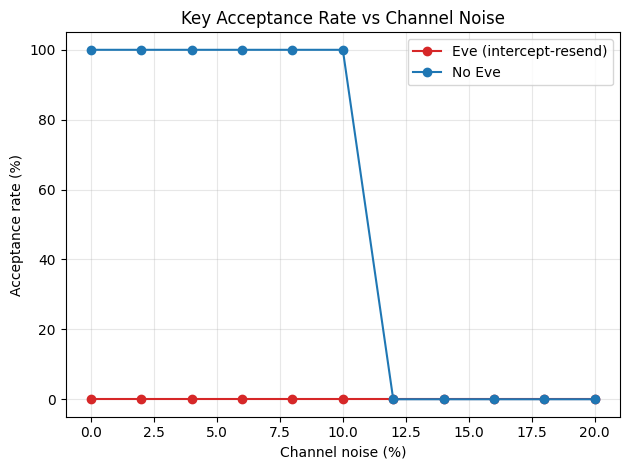

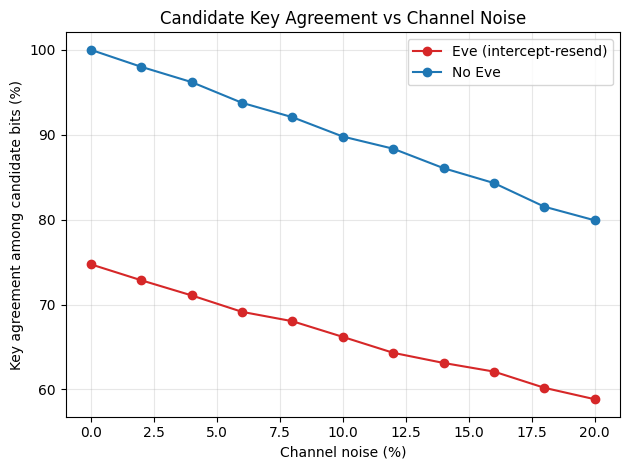

In [6]:
plot_noise_results(summary, show=True)

## 7. Extension: Eve intercepts only a fraction of the qubits
Theory: QBER = 25% x fraction. A careful Eve can stay under the 11% threshold.

In [ ]:
frac = eve_fraction_experiment(trials=5)
plot_eve_fraction(frac, show=True)
frac.round(3)

Completed: Eve intercepts 0%
Completed: Eve intercepts 10%
Completed: Eve intercepts 20%
Completed: Eve intercepts 30%
Completed: Eve intercepts 40%
